In [ ]:
#imports
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
#File path
folder = Path("/content/drive/MyDrive/Hospital_Data/OG_data")

# Exclude previously generated merged files
excluded_files = []
files = sorted([f for f in folder.glob("*.csv") if f.name not in excluded_files])

#columns to be extracted -> included the ones highlghted in the excel sheet
keep_cols = [
    "FAC_NO",
    "FAC_NAME",
    "BEG_DATE",
    "END_DATE",
    "DAY_PER",
    "DATA_IND",
    "AUDIT_IND",
    "COUNTY",
    "HSA",
    "HFPA",
    "TYPE_CNTRL",
    "TYPE_CARE",
    "TYPE_HOSP",
    "TEACH_RURL",
    "PHONE",
    "ADDRESS",
    "CITY",
    "ZIP_CODE",
    "CEO",
    "CEO_TITLE",
    "WEB_SITE",
    "OWNER",
    "DAY_TOT",
    "DIS_TOT",
    "DIS_NURSRY",
    "VIS_TOT",
    "VIS_ER",
    "VIS_CLIN",
    "VIS_REF_OP",
    "OP_MIN_IP",
    "OP_MIN_OP",
    "SURG_IP",
    "SURG_OP",
    "NAT_0BIRTHS",
    "C_SECTIONS",
    "EXP_DLY",
    "EXP_AMB",
    "EXP_ANC",
    "EXP_PIP",
    "EXP_POP",
    "EXP_RES",
    "EXP_ED",
    "EXP_GEN",
    "EXP_FISC",
    "EXP_ADM",
    "EXP_UNASSG",
    "EXP_SAL",
    "EXP_BEN",
    "EXP_PHYS",
    "EXP_OTHPRO",
    "EXP_SUPP",
    "EXP_PURCH",
    "EXP_DEPRE",
    "EXP_LEASES",
    "EXP_INSUR",
    "EXP_INTRST",
    "EXP_OTH",
    "HOSP_FTE",
    "NURS_FTE",
    "PROD_HRS",
    "NON_PRD_HR",
    "PAID_HRS",
    "MED_STAFF",
    "STDNT_FTE",
    "PRD_HR_DLY",
    "PRD_HR_AMB",
    "PRD_HR_ANC",
    "PRD_HR_ED",
    "PRD_HR_GEN",
    "PRD_HR_FIS",
    "PRD_HR_ADM",
    "PRD_HR_NON",
    "PD_HR_DLY",
    "PD_HR_AMB",
    "PD_HR_ANC",
    "PD_HR_ED",
    "PD_HR_GEN",
    "PD_HR_FIS",
    "PD_HR_ADM",
    "PD_HR_NON"
]

# store each cleaned dataframe
dfs = []
# store hospital ID sets from each file
hospital_sets = []

for f in files:
    df = pd.read_csv(f)

    # keep only columns that exist
    cols = [c for c in keep_cols if c in df.columns]
    df = df[cols].copy()

    # make sure hospital_id is consistent
    df["FAC_NO"] = df["FAC_NO"].astype(str).str.strip()

    dfs.append(df)
    hospital_sets.append(set(df["FAC_NO"].dropna().unique()))

# hospitals present in every file
common_hospitals = set.intersection(*hospital_sets)

# filter each dataframe to only those hospitals
filtered_dfs = [
    df[df["FAC_NO"].isin(common_hospitals)].copy()
    for df in dfs
]

# combine into one dataset
merged = pd.concat(filtered_dfs, ignore_index=True)

print("Hospitals in every file:", len(common_hospitals))
print("Rows in merged file:", len(merged))

Hospitals in every file: 357
Rows in merged file: 1805


In [ ]:
#Null values
print("Null values in the merged dataset:")
display(merged.isnull().sum())

Null values in the merged dataset:


,0
FAC_NO,0
FAC_NAME,0
BEG_DATE,0
END_DATE,0
DAY_PER,0
...,...
PD_HR_GEN,0
PD_HR_FIS,0
PD_HR_ADM,0
PD_HR_NON,359


In [ ]:
#Panel of Hospitals
'''
unique_hospitals = merged['FAC_NAME'].unique()
print(unique_hospitals)
'''

"\nunique_hospitals = merged['FAC_NAME'].unique()\nprint(unique_hospitals)\n"

In [ ]:
#Defining Expenses

# Define patient expense columns
patient_expense_cols = [
    'EXP_DLY',
    'EXP_AMB',
    'EXP_ANC',
    'EXP_PIP',
    'EXP_POP'
]

# Define overhead expense columns
overhead_expense_cols = [
    'EXP_RES',
    'EXP_ED',
    'EXP_GEN',
    'EXP_FISC',
    'EXP_ADM',
    'EXP_UNASSG'
]


In [ ]:
#Creating year column
merged_with_end_year = merged.copy()

# Ensure 'END_DATE' is in datetime format, handling mixed formats and coercing errors
merged_with_end_year['END_DATE'] = pd.to_datetime(merged_with_end_year['END_DATE'], format='mixed', errors='coerce')

# Assign 'YEAR' based on 'END_DATE'
merged_with_end_year['YEAR'] = merged_with_end_year['END_DATE'].dt.year

print("New DataFrame 'merged_with_end_year' created with 'YEAR' column based on END_DATE.")
display(merged_with_end_year.head())

New DataFrame 'merged_with_end_year' created with 'YEAR' column based on END_DATE.


,FAC_NO,FAC_NAME,BEG_DATE,END_DATE,DAY_PER,DATA_IND,AUDIT_IND,COUNTY,HSA,HFPA,...,PD_HR_DLY,PD_HR_AMB,PD_HR_ANC,PD_HR_ED,PD_HR_GEN,PD_HR_FIS,PD_HR_ADM,PD_HR_NON,NAT_0BIRTHS,YEAR
0,106010846,ALAMEDA COUNTY MEDICAL CENTER,2003-07-01T00:00:00,2004-06-30,366,AUDITED,EXCL. IND. AUDIT,ALAMEDA,5,417,...,1276968,786518,619394,282217,892239,407129,482813,NaN,NaN,2004
1,106010735,ALAMEDA HOSPITAL,2003-07-01T00:00:00,2004-06-30,366,AUDITED,INCL. IND. AUDIT,ALAMEDA,5,417,...,245518,43688,203882,0,152714,72787,107765,NaN,NaN,2004
2,106190017,ALHAMBRA HOSPITAL - ALHAMBRA,2003-07-01T00:00:00,2004-06-30,366,AUDITED,EXCL. IND. AUDIT,LOS ANGELES,11,913,...,421982,33666,200830,0,123190,65041,101170,NaN,NaN,2004
3,106010739,ALTA BATES SUMMIT MED CTR-ALTA BATES CAM,2004-01-01T00:00:00,2004-12-31,366,AUDITED,INCL. IND. AUDIT,ALAMEDA,5,415,...,1787592,227360,1203534,6377,805001,172990,388515,NaN,NaN,2004
4,106010937,ALTA BATES SUMMIT MED CTR-SUMMIT-HAWTHOR,2004-01-01T00:00:00,2004-12-31,366,AUDITED,INCL. IND. AUDIT,ALAMEDA,5,417,...,1268124,158076,906146,340026,690224,176223,231959,NaN,NaN,2004


In [ ]:
# Calculate total patient expenses for each record in merged_with_end_year
merged_with_end_year['Patient_Expenses'] = merged_with_end_year[patient_expense_cols].sum(axis=1)

# Calculate total overhead expenses for each record in merged_with_end_year
merged_with_end_year['Overhead_Expenses'] = merged_with_end_year[overhead_expense_cols].sum(axis=1)
# Group by YEAR (derived from END_DATE) and sum patient and overhead expenses
yearly_expenses_end_date = merged_with_end_year.groupby('YEAR')[['Patient_Expenses', 'Overhead_Expenses']].sum().reset_index()

# Calculate the total combined expenses for patient and overhead
yearly_expenses_end_date['Total_Combined_Expenses'] = yearly_expenses_end_date['Patient_Expenses'] + yearly_expenses_end_date['Overhead_Expenses']

# Calculate the percentage of Patient Expenses
yearly_expenses_end_date['Patient_Expense_Percentage'] = (yearly_expenses_end_date['Patient_Expenses'] / yearly_expenses_end_date['Total_Combined_Expenses']) * 100

# Calculate the percentage of Overhead Expenses
yearly_expenses_end_date['Overhead_Expense_Percentage'] = (yearly_expenses_end_date['Overhead_Expenses'] / yearly_expenses_end_date['Total_Combined_Expenses']) * 100

display(yearly_expenses_end_date[['YEAR', 'Patient_Expense_Percentage', 'Overhead_Expense_Percentage']])

,YEAR,Patient_Expense_Percentage,Overhead_Expense_Percentage
0,2004,60.890059,39.109941
1,2009,61.561269,38.438731
2,2014,59.017496,40.982504
3,2019,59.423566,40.576434
4,2024,59.983245,40.016755


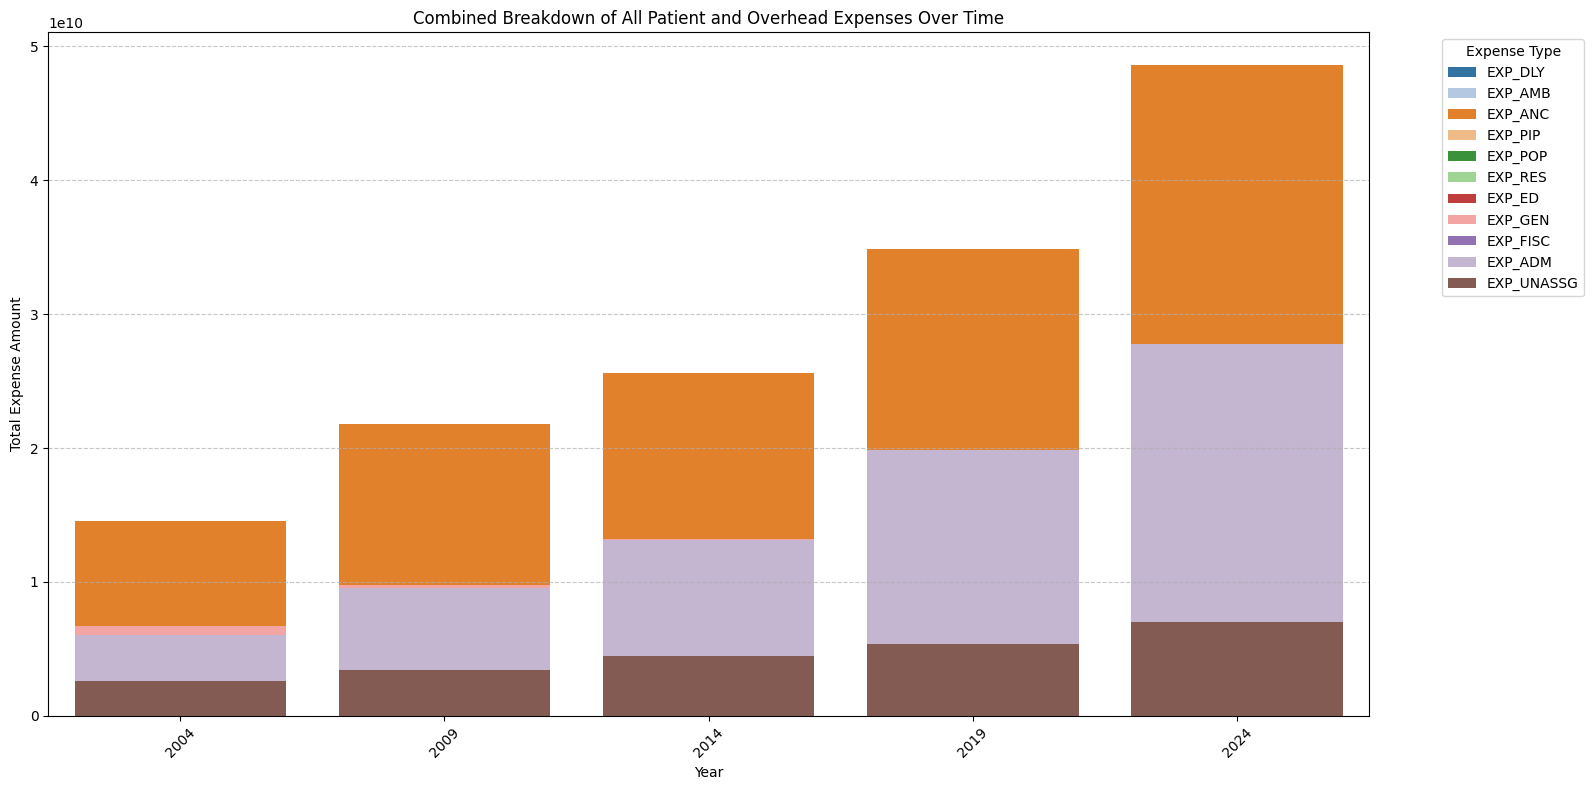

In [ ]:
# Combine all expense columns
all_expense_cols = patient_expense_cols + overhead_expense_cols

# Prepare data for the combined breakdown
all_expenses_breakdown = merged_with_end_year[['YEAR'] + all_expense_cols].groupby('YEAR')[all_expense_cols].sum().reset_index()
all_expenses_melted = all_expenses_breakdown.melt(id_vars=['YEAR'], var_name='Expense_Type', value_name='Amount')

# Set the figure size
plt.figure(figsize=(16, 8))

# Create a stacked bar chart for the combined expense breakdown
sns.barplot(x='YEAR', y='Amount', hue='Expense_Type', data=all_expenses_melted, palette='tab20', dodge=False)

plt.title('Combined Breakdown of All Patient and Overhead Expenses Over Time')
plt.xlabel('Year')
plt.ylabel('Total Expense Amount')
plt.legend(title='Expense Type', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


 Total Operating Expenses by Year:


,YEAR,Patient_Expenses,Overhead_Expenses,Total_Combined_Expenses
0,2004,27811315444,17863325095,45674640539
1,2009,41699538308,26037107213,67736645521
2,2014,50405612824,35002302815,85407915639
3,2019,70766665789,48321887799,119088553588
4,2024,97475421390,65028994522,162504415912


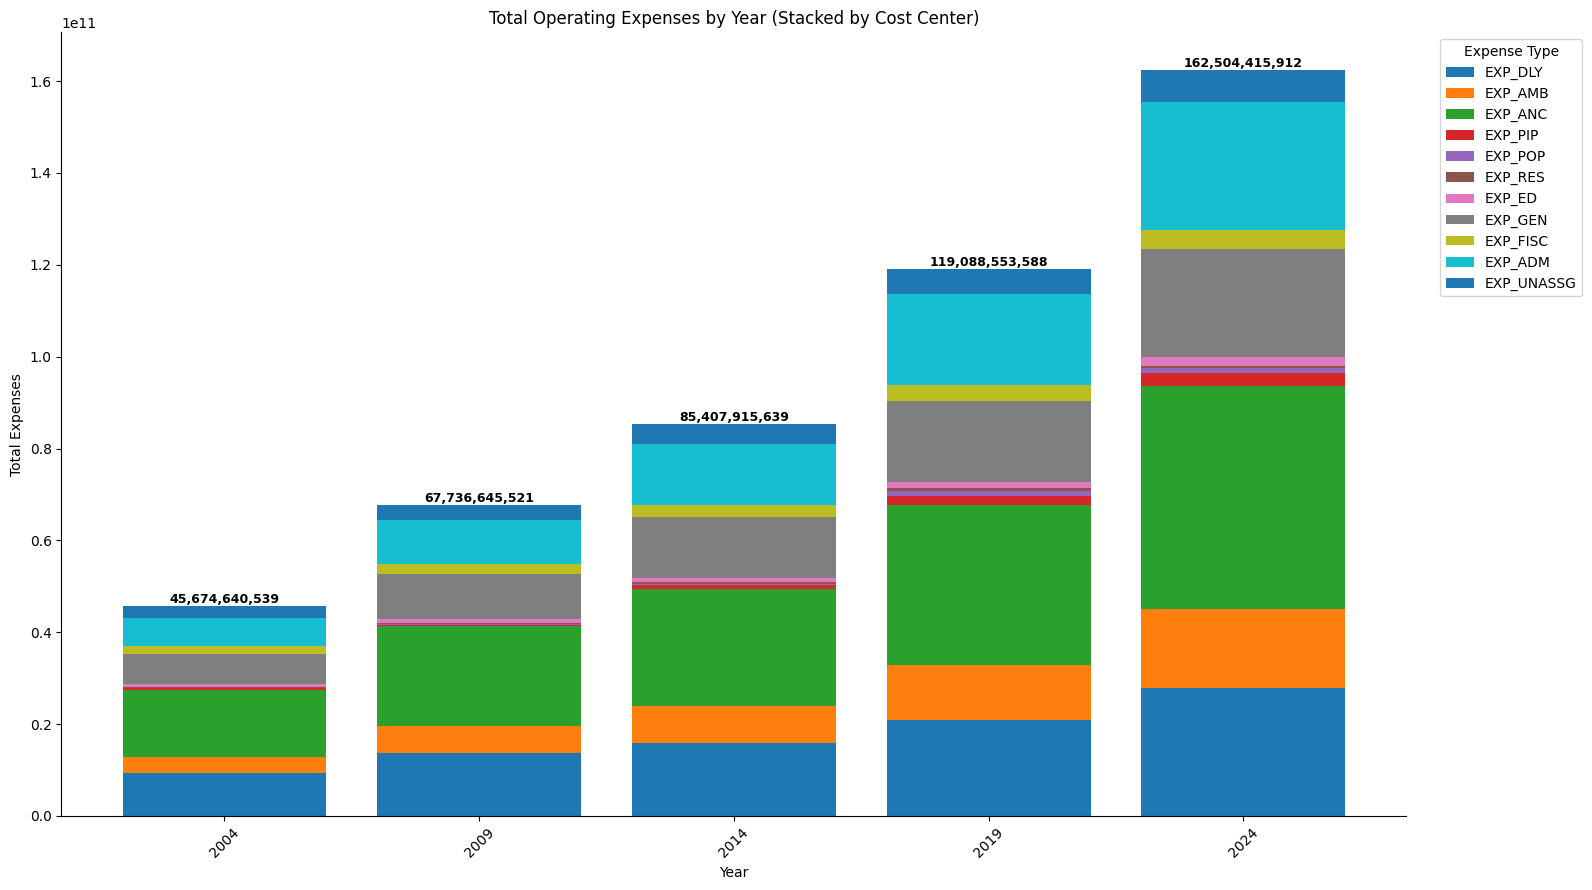

In [ ]:
# Using the predefined all_expense_cols from earlier in the notebook
# all_expense_cols = [
#     "EXP_DLY",    # Daily Hospital Services
#     "EXP_AMB",    # Ambulatory Services
#     "EXP_ANC",    # Ancillary Services
#     "EXP_PIP",    # Purchased Inpatient Services
#     "EXP_POP",    # Purchased Outpatient Services
#     "EXP_RES",    # Research
#     "EXP_ED",     # Education
#     "EXP_GEN",    # General Services
#     "EXP_FISC",   # Fiscal Services
#     "EXP_ADM",    # Administrative Services
#     "EXP_UNASSG"  # Unassigned Costs
# ]

# Keep only valid columns (in case one is missing)
# This step is redundant if all_expense_cols is already correctly defined in the notebook context
# We will use the existing all_expense_cols and filter merged_with_end_year
valid_expense_cols = [c for c in all_expense_cols if c in merged_with_end_year.columns]

# --- 3) Sum expenses by year ---
yearly = (
    merged_with_end_year.groupby("YEAR", as_index=False)[valid_expense_cols]
      .sum()
      .sort_values("YEAR")
)

# Optional: total operating expense per year
yearly["TOTAL_EXP"] = yearly[valid_expense_cols].sum(axis=1)

# --- 4) Plot stacked bar chart ---
fig, ax = plt.subplots(figsize=(16, 9))

bottom = pd.Series([0] * len(yearly), index=yearly.index)

for col in valid_expense_cols:
    ax.bar(yearly["YEAR"].astype(str), yearly[col], bottom=bottom, label=col)
    bottom = bottom + yearly[col]

# --- 5) Add total labels on top of each bar ---
for i, total in enumerate(yearly["TOTAL_EXP"]):
    ax.text(
        i,
        total,
        f"{total:,.0f}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )
print("\n Total Operating Expenses by Year:")
display(yearly_expenses_end_date[['YEAR', 'Patient_Expenses', 'Overhead_Expenses','Total_Combined_Expenses']])

ax.set_title("Total Operating Expenses by Year (Stacked by Cost Center)")
ax.set_xlabel("Year")
ax.set_ylabel("Total Expenses")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Expense Type")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Based on the new definition:
# Total FTE = HOSP_FTE
# Other FTE = HOSP_FTE - (NURS_FTE + STDNT_FTE)

merged_with_end_year['Other_FTE'] = merged_with_end_year['HOSP_FTE'] - (merged_with_end_year['NURS_FTE'] + merged_with_end_year['STDNT_FTE'])


print("DataFrame with 'Total_FTE' and 'Other_FTE' columns added:")
display(merged_with_end_year[['FAC_NO', 'YEAR', 'HOSP_FTE', 'NURS_FTE', 'STDNT_FTE', 'Other_FTE']].head())

DataFrame with 'Total_FTE' and 'Other_FTE' columns added:


,FAC_NO,YEAR,HOSP_FTE,NURS_FTE,STDNT_FTE,Other_FTE
0,106010846,2004,2168,572,102,1494
1,106010735,2004,382,118,0,264
2,106190017,2004,429,178,0,251
3,106010739,2004,2062,690,0,1372
4,106010937,2004,1599,555,2,1042


In [ ]:
 #Calculate AVG_WAGE using EXP_SAL and HOSP_FTE
# Handle potential division by zero for HOSP_FTE
merged_with_end_year['AVG_WAGE'] = merged_with_end_year.apply(lambda row: row['EXP_SAL'] / row['HOSP_FTE'] if row['HOSP_FTE'] != 0 else 0, axis=1)

# Calculate Total_Combined_Expenses at the record level in merged_with_end_year
merged_with_end_year['Total_Combined_Expenses'] = merged_with_end_year['Patient_Expenses'] + merged_with_end_year['Overhead_Expenses']

print("DataFrame with 'AVG_WAGE' column added (first 5 rows):")
display(merged_with_end_year[['FAC_NO', 'YEAR', 'EXP_SAL', 'HOSP_FTE', 'NURS_FTE', 'STDNT_FTE', 'Other_FTE', 'AVG_WAGE', 'Total_Combined_Expenses']].head())
yearly_expenses_fte = merged_with_end_year.groupby('YEAR')[['Total_Combined_Expenses', 'HOSP_FTE']].sum().reset_index()
yearly_avg_wage = merged_with_end_year.groupby('YEAR')['AVG_WAGE'].mean().reset_index()

DataFrame with 'AVG_WAGE' column added (first 5 rows):


,FAC_NO,YEAR,EXP_SAL,HOSP_FTE,NURS_FTE,STDNT_FTE,Other_FTE,AVG_WAGE,Total_Combined_Expenses
0,106010846,2004,137744075,2168,572,102,1494,63535.089945,323933479
1,106010735,2004,21300626,382,118,0,264,55760.801047,52241573
2,106190017,2004,18569143,429,178,0,251,43284.715618,50444188
3,106010739,2004,134753463,2062,690,0,1372,65350.854995,435102594
4,106010937,2004,117317925,1599,555,2,1042,73369.559099,326355826


/tmp/ipykernel_65724/740510498.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='YEAR', y='AVG_WAGE', data=yearly_avg_wage, palette='viridis')


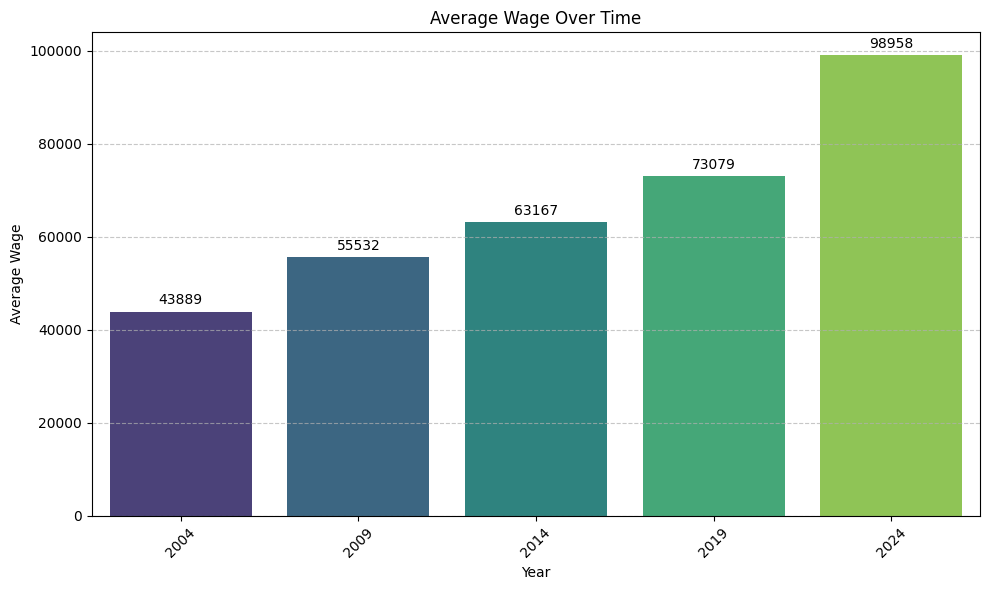

In [ ]:
plt.figure(figsize=(10, 6))
ax = sns.barplot(x='YEAR', y='AVG_WAGE', data=yearly_avg_wage, palette='viridis')

plt.title('Average Wage Over Time')
plt.xlabel('Year')
plt.ylabel('Average Wage')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)

# Add labels on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', label_type='edge', padding=3)

plt.tight_layout()
plt.show()

Average Wage by Year and Hospital Type:


,YEAR,TYPE_HOSP,AVG_WAGE
0,2004,COMPARABLE,48716.409360
1,2004,KAISER,0.000000
2,2004,LTC EMPHASIS,47218.118295
3,2004,OTHER NON-COMPARABLE,0.000000
4,2004,PHF,16924.869827


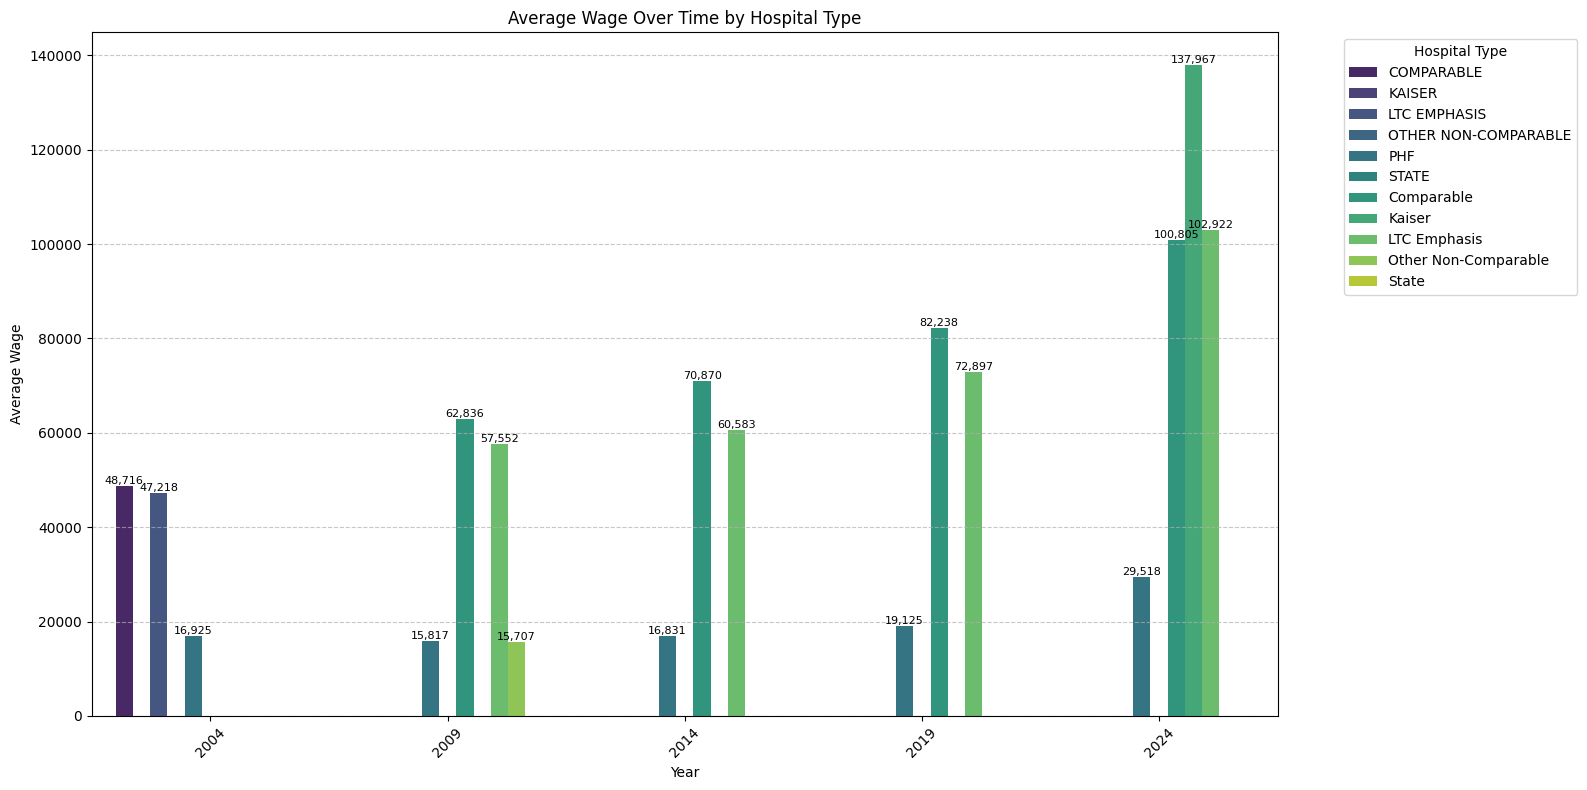

In [ ]:
# Calculate average wage by year and hospital type
yearly_avg_wage_by_type = merged_with_end_year.groupby(['YEAR', 'TYPE_HOSP'])['AVG_WAGE'].mean().reset_index()

print("Average Wage by Year and Hospital Type:")
display(yearly_avg_wage_by_type.head())

# Plot the average wage by year for each hospital type as a grouped bar chart
plt.figure(figsize=(16, 8)) # Increased figure size for better readability
ax = sns.barplot(x='YEAR', y='AVG_WAGE', hue='TYPE_HOSP', data=yearly_avg_wage_by_type, palette='viridis')

plt.title('Average Wage Over Time by Hospital Type')
plt.xlabel('Year')
plt.ylabel('Average Wage')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.xticks(rotation=45)
plt.legend(title='Hospital Type', bbox_to_anchor=(1.05, 1), loc='upper left')

# Add labels on top of each bar
for container in ax.containers:
    for bar in container:
        height = bar.get_height()
        if height > 0: # Only label non-zero bars
            ax.text(bar.get_x() + bar.get_width() / 2, height, f'{height:,.0f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

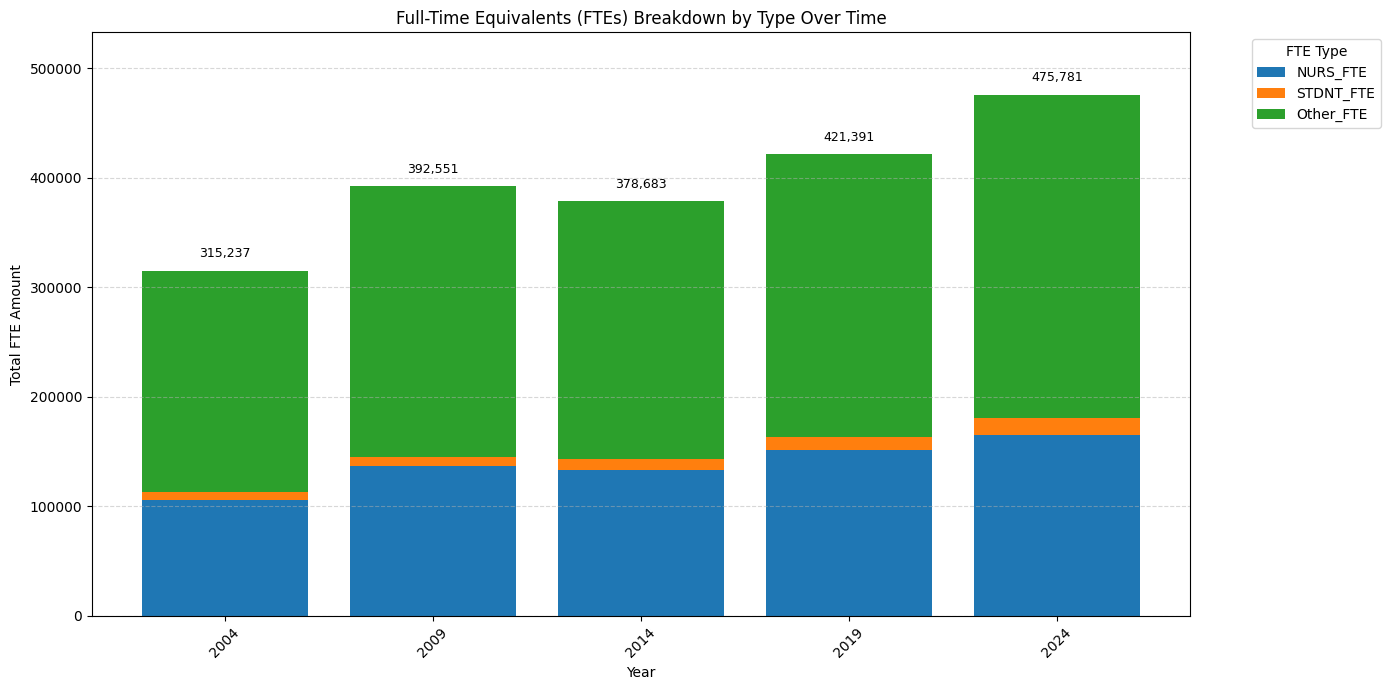

In [ ]:
fte_cols = ['NURS_FTE', 'STDNT_FTE', 'Other_FTE']

# Group by year
fte_breakdown = (
    merged_with_end_year
    .groupby('YEAR')[fte_cols]
    .sum()
    .reset_index()
    .sort_values('YEAR')
)

years = fte_breakdown['YEAR'].astype(str).tolist()
x = np.arange(len(years))

# Use a numpy array for stacking
bottom = np.zeros(len(fte_breakdown))

fig, ax = plt.subplots(figsize=(14, 7))

for col in fte_cols:
    ax.bar(x, fte_breakdown[col].values, bottom=bottom, label=col)
    bottom += fte_breakdown[col].values

# Total labels on top
yearly_total_ftes = fte_breakdown[fte_cols].sum(axis=1).values
offset = yearly_total_ftes.max() * 0.02

for i, total in enumerate(yearly_total_ftes):
    ax.text(
        x[i],
        total + offset,
        f'{total:,.0f}',
        ha='center',
        va='bottom',
        fontsize=9,
        color='black'
    )

ax.set_title('Full-Time Equivalents (FTEs) Breakdown by Type Over Time')
ax.set_xlabel('Year')
ax.set_ylabel('Total FTE Amount')
ax.set_xticks(x)
ax.set_xticklabels(years, rotation=45)
ax.legend(title='FTE Type', bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.set_ylim(0, yearly_total_ftes.max() * 1.12)

plt.tight_layout()
plt.show()

### Simple Linear Regression: Total Combined Expenses vs. HOSP_FTE

In [ ]:
cols = [
    'DAY_TOT',
    'DIS_TOT',
    'DIS_NURSRY',
    'VIS_TOT',
    'VIS_ER',
    'VIS_CLIN',
    'VIS_REF_OP',
    'OP_MIN_IP',
    'OP_MIN_OP',
    'SURG_IP',
    'SURG_OP',
    'NAT_0BIRTHS',
    'C_SECTIONS'
]

yearly_totals = (
    merged_with_end_year
    .groupby('YEAR')[cols]
    .sum()
    .reset_index()
)

display(yearly_totals)

,YEAR,DAY_TOT,DIS_TOT,DIS_NURSRY,VIS_TOT,VIS_ER,VIS_CLIN,VIS_REF_OP,OP_MIN_IP,OP_MIN_OP,SURG_IP,SURG_OP,NAT_0BIRTHS,C_SECTIONS
0,2004,18965277,2987923,352639,38224761,8265668,12351061,14717580,126793354,88519354,899327,1205854,0.0,112482
1,2009,18984196,3109950,364069,42033493,10570592,13236307,15525776,125029086,88428573,873510,1143095,0.0,147633
2,2014,17905478,2985720,287566,43169743,12228671,14326814,14208786,121233461,95659001,788538,1143678,0.0,142911
3,2019,18731742,3062472,236037,47813688,13517598,18612510,14095859,117780418,108789590,770753,1290528,0.0,117718
4,2024,19500176,2996434,196628,54437170,14074553,20823149,17824397,116920877,126801408,689557,1392288,236537.0,108807


In [ ]:
merged_with_end_year.head()

,FAC_NO,FAC_NAME,BEG_DATE,END_DATE,DAY_PER,DATA_IND,AUDIT_IND,COUNTY,HSA,HFPA,...,PD_HR_FIS,PD_HR_ADM,PD_HR_NON,NAT_0BIRTHS,YEAR,Patient_Expenses,Overhead_Expenses,Other_FTE,AVG_WAGE,Total_Combined_Expenses
0,106010846,ALAMEDA COUNTY MEDICAL CENTER,2003-07-01T00:00:00,2004-06-30,366,AUDITED,EXCL. IND. AUDIT,ALAMEDA,5,417,...,407129,482813,NaN,NaN,2004,163621843,160311636,1494,63535.089945,323933479
1,106010735,ALAMEDA HOSPITAL,2003-07-01T00:00:00,2004-06-30,366,AUDITED,INCL. IND. AUDIT,ALAMEDA,5,417,...,72787,107765,NaN,NaN,2004,30851410,21390163,264,55760.801047,52241573
2,106190017,ALHAMBRA HOSPITAL - ALHAMBRA,2003-07-01T00:00:00,2004-06-30,366,AUDITED,EXCL. IND. AUDIT,LOS ANGELES,11,913,...,65041,101170,NaN,NaN,2004,31497779,18946409,251,43284.715618,50444188
3,106010739,ALTA BATES SUMMIT MED CTR-ALTA BATES CAM,2004-01-01T00:00:00,2004-12-31,366,AUDITED,INCL. IND. AUDIT,ALAMEDA,5,415,...,172990,388515,NaN,NaN,2004,277537023,157565571,1372,65350.854995,435102594
4,106010937,ALTA BATES SUMMIT MED CTR-SUMMIT-HAWTHOR,2004-01-01T00:00:00,2004-12-31,366,AUDITED,INCL. IND. AUDIT,ALAMEDA,5,417,...,176223,231959,NaN,NaN,2004,202291344,124064482,1042,73369.559099,326355826


In [ ]:
merged_with_end_year.columns

Index(['FAC_NO', 'FAC_NAME', 'BEG_DATE', 'END_DATE', 'DAY_PER', 'DATA_IND',
       'AUDIT_IND', 'COUNTY', 'HSA', 'HFPA', 'TYPE_CNTRL', 'TYPE_CARE',
       'TYPE_HOSP', 'TEACH_RURL', 'PHONE', 'ADDRESS', 'CITY', 'ZIP_CODE',
       'CEO', 'CEO_TITLE', 'WEB_SITE', 'OWNER', 'DAY_TOT', 'DIS_TOT',
       'DIS_NURSRY', 'VIS_TOT', 'VIS_ER', 'VIS_CLIN', 'VIS_REF_OP',
       'OP_MIN_IP', 'OP_MIN_OP', 'SURG_IP', 'SURG_OP', 'C_SECTIONS', 'EXP_DLY',
       'EXP_AMB', 'EXP_ANC', 'EXP_PIP', 'EXP_POP', 'EXP_RES', 'EXP_ED',
       'EXP_GEN', 'EXP_FISC', 'EXP_ADM', 'EXP_UNASSG', 'EXP_SAL', 'EXP_BEN',
       'EXP_PHYS', 'EXP_OTHPRO', 'EXP_SUPP', 'EXP_PURCH', 'EXP_DEPRE',
       'EXP_LEASES', 'EXP_INSUR', 'EXP_INTRST', 'EXP_OTH', 'HOSP_FTE',
       'NURS_FTE', 'PROD_HRS', 'NON_PRD_HR', 'PAID_HRS', 'MED_STAFF',
       'STDNT_FTE', 'PRD_HR_DLY', 'PRD_HR_AMB', 'PRD_HR_ANC', 'PRD_HR_ED',
       'PRD_HR_GEN', 'PRD_HR_FIS', 'PRD_HR_ADM', 'PRD_HR_NON', 'PD_HR_DLY',
       'PD_HR_AMB', 'PD_HR_ANC', 'PD_HR_ED', 'PD

Slope (effect of X on Y): 3728.0850436310484
Intercept: 71827325.25098407
R^2: 0.23751117836697078


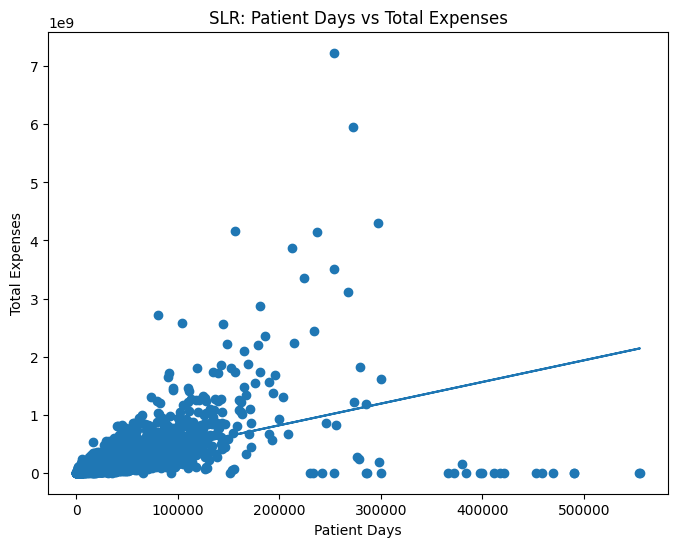

In [ ]:
# -----------------------------
# Choose variables
# -----------------------------
X = merged_with_end_year[['DAY_TOT']]   # independent variable
y = merged_with_end_year['Total_Combined_Expenses']  # dependent variable

# -----------------------------
# Fit regression model
# -----------------------------
model = LinearRegression()
model.fit(X, y)

# -----------------------------
# Get results
# -----------------------------
slope = model.coef_[0]
intercept = model.intercept_
r2 = model.score(X, y)

print(f"Slope (effect of X on Y): {slope}")
print(f"Intercept: {intercept}")
print(f"R^2: {r2}")

# -----------------------------
# Plot
# -----------------------------
plt.figure(figsize=(8,6))
plt.scatter(X, y)
plt.plot(X, model.predict(X))  # regression line
plt.xlabel('Patient Days')
plt.ylabel('Total Expenses')
plt.title('SLR: Patient Days vs Total Expenses')
plt.show()

Slope (effect of X on Y): 51.887782143194045
Intercept: -20732457.78813228
R^2: 0.824895639982551


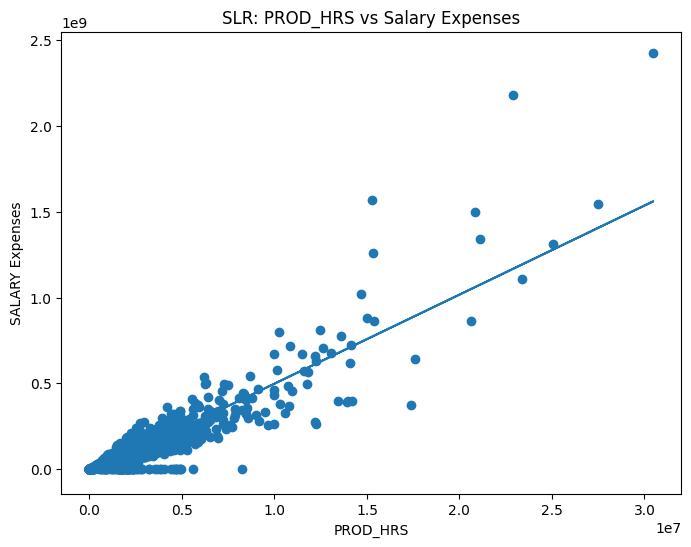

In [ ]:
X = merged_with_end_year[['PROD_HRS']]
y = merged_with_end_year['EXP_SAL']

# -----------------------------
# Fit regression model
# -----------------------------
model = LinearRegression()
model.fit(X, y)

# -----------------------------
# Get results
# -----------------------------
slope = model.coef_[0]
intercept = model.intercept_
r2 = model.score(X, y)

print(f"Slope (effect of X on Y): {slope}")
print(f"Intercept: {intercept}")
print(f"R^2: {r2}")

# -----------------------------
# Plot
# -----------------------------
plt.figure(figsize=(8,6))
plt.scatter(X, y)
plt.plot(X, model.predict(X))  # regression line
plt.xlabel('PROD_HRS')
plt.ylabel('SALARY Expenses')
plt.title('SLR: PROD_HRS vs Salary Expenses')
plt.show()

Slope: 278308.26437367185
Intercept: -39696437.2675809
R^2: 0.8246385442547238


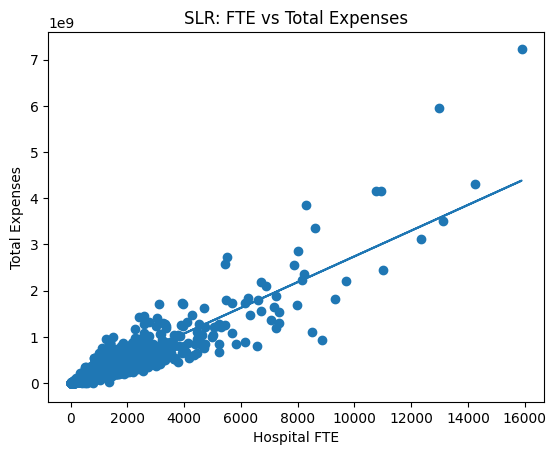

In [ ]:
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

X = merged_with_end_year[['HOSP_FTE']]
y = merged_with_end_year['Total_Combined_Expenses']

model = LinearRegression()
model.fit(X, y)

print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)
print("R^2:", model.score(X, y))

# Plot
plt.scatter(X, y)
plt.plot(X, model.predict(X))
plt.xlabel('Hospital FTE')
plt.ylabel('Total Expenses')
plt.title('SLR: FTE vs Total Expenses')
plt.show()

In [ ]:
from sklearn.linear_model import LinearRegression

for year in sorted(merged_with_end_year['YEAR'].unique()):
    df = merged_with_end_year[merged_with_end_year['YEAR'] == year]

    X = df[['HOSP_FTE']]
    y = df['Total_Combined_Expenses']

    model = LinearRegression().fit(X, y)

    print(f"Year: {year}")
    print(f"Cost per FTE (slope): {model.coef_[0]}")
    print(f"R^2: {model.score(X, y)}\n")

Year: 2004
Cost per FTE (slope): 151642.06483098987
R^2: 0.924134070434303

Year: 2009
Cost per FTE (slope): 175710.26073095962
R^2: 0.9091317419992356

Year: 2014
Cost per FTE (slope): 230459.1077478723
R^2: 0.9121601626689925

Year: 2019
Cost per FTE (slope): 294666.2203040452
R^2: 0.9051442903032069

Year: 2024
Cost per FTE (slope): 354941.0964569505
R^2: 0.9068217715751693



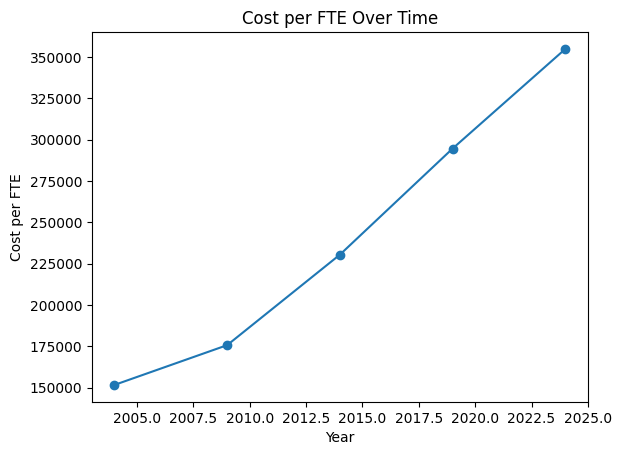

In [ ]:
slopes = []

years = sorted(merged_with_end_year['YEAR'].unique())

for year in years:
    df = merged_with_end_year[merged_with_end_year['YEAR'] == year]

    model = LinearRegression().fit(
        df[['HOSP_FTE']],
        df['Total_Combined_Expenses']
    )

    slopes.append(model.coef_[0])

import matplotlib.pyplot as plt

plt.plot(years, slopes, marker='o')
plt.xlabel('Year')
plt.ylabel('Cost per FTE')
plt.title('Cost per FTE Over Time')
plt.show()

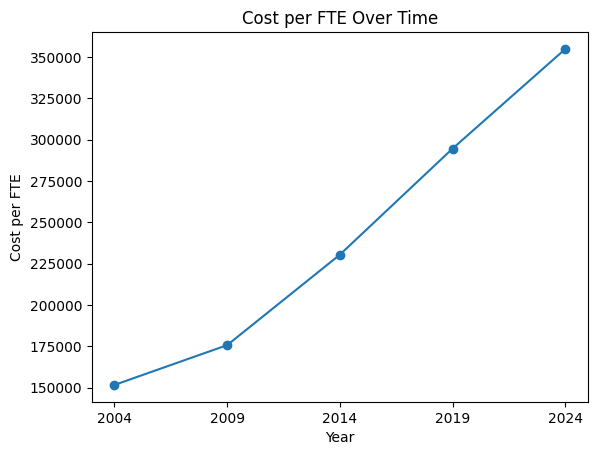

In [ ]:
years = sorted(merged_with_end_year['YEAR'].unique())
plt.plot(years, slopes, marker='o')
plt.xlabel('Year')
plt.ylabel('Cost per FTE')
plt.title('Cost per FTE Over Time')
plt.xticks(years)  # ensures only your years show
plt.show()

In [ ]:
import pandas as pd
from sklearn.linear_model import LinearRegression

results = []

for year in sorted(merged_with_end_year['YEAR'].unique()):
    df = merged_with_end_year[merged_with_end_year['YEAR'] == year]

    X = df[['HOSP_FTE']]
    y = df['Total_Combined_Expenses']

    model = LinearRegression().fit(X, y)

    results.append({
        'Year': year,
        'Cost_per_FTE': model.coef_[0],
        'Intercept': model.intercept_,
        'R_squared': model.score(X, y)
    })

# Convert to DataFrame
results_df = pd.DataFrame(results)

# Optional: format numbers
results_df['Cost_per_FTE'] = results_df['Cost_per_FTE'].round(0)
results_df['Intercept'] = results_df['Intercept'].round(0)
results_df['R_squared'] = results_df['R_squared'].round(3)

results_df

,Year,Cost_per_FTE,Intercept,R_squared
0,2004,151642.0,-5929106.0,0.924
1,2009,175710.0,-3450120.0,0.909
2,2014,230459.0,-5146494.0,0.912
3,2019,294666.0,-14036297.0,0.905
4,2024,354941.0,-17547697.0,0.907


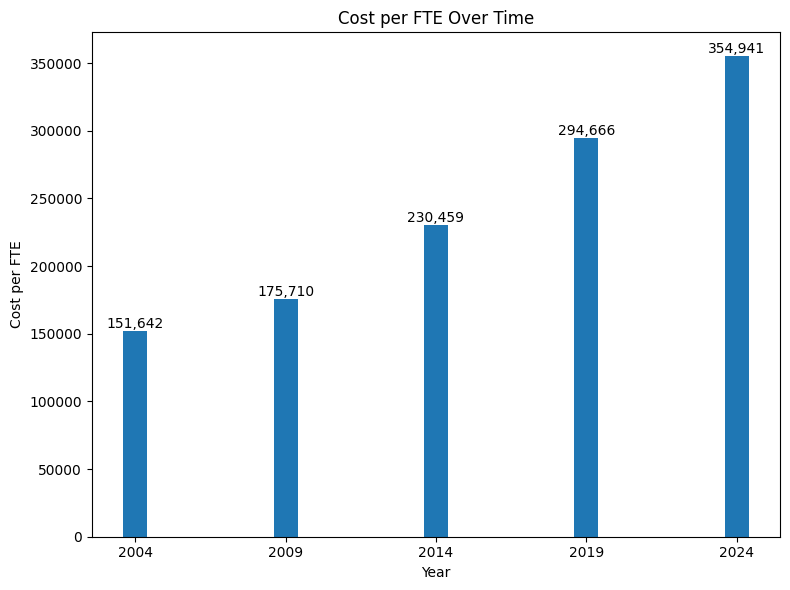

In [ ]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

years = [2004, 2009, 2014, 2019, 2024]
slopes = []

# Calculate slope (cost per FTE) for each year
for year in years:
    df = merged_with_end_year[merged_with_end_year['YEAR'] == year]

    model = LinearRegression().fit(
        df[['HOSP_FTE']],
        df['Total_Combined_Expenses']
    )

    slopes.append(model.coef_[0])

# -----------------------------
# Plot bar chart
# -----------------------------
plt.figure(figsize=(8,6))
bars = plt.bar(years, slopes)

plt.xlabel('Year')
plt.ylabel('Cost per FTE')
plt.title('Cost per FTE Over Time')

# -----------------------------
# Add value labels on top
# -----------------------------
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f'{int(height):,}',  # formatted with commas
        ha='center',
        va='bottom'
    )

plt.xticks(years)
plt.tight_layout()
plt.show()

In [ ]:
merged_with_end_year['Employee_Cost'] = (
    merged_with_end_year['EXP_SAL'] +
    merged_with_end_year['EXP_BEN']
)
merged_with_end_year.head()

,FAC_NO,FAC_NAME,BEG_DATE,END_DATE,DAY_PER,DATA_IND,AUDIT_IND,COUNTY,HSA,HFPA,...,PD_HR_ADM,PD_HR_NON,NAT_0BIRTHS,YEAR,Patient_Expenses,Overhead_Expenses,Other_FTE,AVG_WAGE,Total_Combined_Expenses,Employee_Cost
0,106010846,ALAMEDA COUNTY MEDICAL CENTER,2003-07-01T00:00:00,2004-06-30,366,AUDITED,EXCL. IND. AUDIT,ALAMEDA,5,417,...,482813,NaN,NaN,2004,163621843,160311636,1494,63535.089945,323933479,198443354
1,106010735,ALAMEDA HOSPITAL,2003-07-01T00:00:00,2004-06-30,366,AUDITED,INCL. IND. AUDIT,ALAMEDA,5,417,...,107765,NaN,NaN,2004,30851410,21390163,264,55760.801047,52241573,33563638
2,106190017,ALHAMBRA HOSPITAL - ALHAMBRA,2003-07-01T00:00:00,2004-06-30,366,AUDITED,EXCL. IND. AUDIT,LOS ANGELES,11,913,...,101170,NaN,NaN,2004,31497779,18946409,251,43284.715618,50444188,23506409
3,106010739,ALTA BATES SUMMIT MED CTR-ALTA BATES CAM,2004-01-01T00:00:00,2004-12-31,366,AUDITED,INCL. IND. AUDIT,ALAMEDA,5,415,...,388515,NaN,NaN,2004,277537023,157565571,1372,65350.854995,435102594,218816815
4,106010937,ALTA BATES SUMMIT MED CTR-SUMMIT-HAWTHOR,2004-01-01T00:00:00,2004-12-31,366,AUDITED,INCL. IND. AUDIT,ALAMEDA,5,417,...,231959,NaN,NaN,2004,202291344,124064482,1042,73369.559099,326355826,168904512


In [ ]:
merged_with_end_year['Labor_Share'] = (
    merged_with_end_year['Employee_Cost'] /
    merged_with_end_year['Total_Combined_Expenses']
)

merged_with_end_year.head()

,FAC_NO,FAC_NAME,BEG_DATE,END_DATE,DAY_PER,DATA_IND,AUDIT_IND,COUNTY,HSA,HFPA,...,PD_HR_NON,NAT_0BIRTHS,YEAR,Patient_Expenses,Overhead_Expenses,Other_FTE,AVG_WAGE,Total_Combined_Expenses,Employee_Cost,Labor_Share
0,106010846,ALAMEDA COUNTY MEDICAL CENTER,2003-07-01T00:00:00,2004-06-30,366,AUDITED,EXCL. IND. AUDIT,ALAMEDA,5,417,...,NaN,NaN,2004,163621843,160311636,1494,63535.089945,323933479,198443354,0.612605
1,106010735,ALAMEDA HOSPITAL,2003-07-01T00:00:00,2004-06-30,366,AUDITED,INCL. IND. AUDIT,ALAMEDA,5,417,...,NaN,NaN,2004,30851410,21390163,264,55760.801047,52241573,33563638,0.642470
2,106190017,ALHAMBRA HOSPITAL - ALHAMBRA,2003-07-01T00:00:00,2004-06-30,366,AUDITED,EXCL. IND. AUDIT,LOS ANGELES,11,913,...,NaN,NaN,2004,31497779,18946409,251,43284.715618,50444188,23506409,0.465988
3,106010739,ALTA BATES SUMMIT MED CTR-ALTA BATES CAM,2004-01-01T00:00:00,2004-12-31,366,AUDITED,INCL. IND. AUDIT,ALAMEDA,5,415,...,NaN,NaN,2004,277537023,157565571,1372,65350.854995,435102594,218816815,0.502909
4,106010937,ALTA BATES SUMMIT MED CTR-SUMMIT-HAWTHOR,2004-01-01T00:00:00,2004-12-31,366,AUDITED,INCL. IND. AUDIT,ALAMEDA,5,417,...,NaN,NaN,2004,202291344,124064482,1042,73369.559099,326355826,168904512,0.517547


In [ ]:
labor_by_year = merged_with_end_year.groupby('YEAR')['Labor_Share'].mean().reset_index()

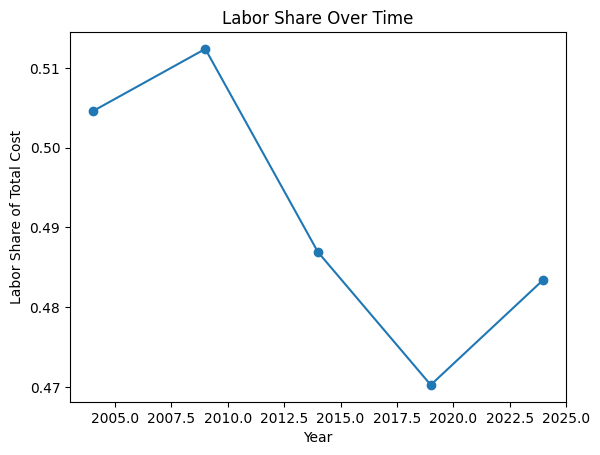

In [ ]:
import matplotlib.pyplot as plt

plt.plot(labor_by_year['YEAR'], labor_by_year['Labor_Share'], marker='o')
plt.xlabel('Year')
plt.ylabel('Labor Share of Total Cost')
plt.title('Labor Share Over Time')
plt.show()

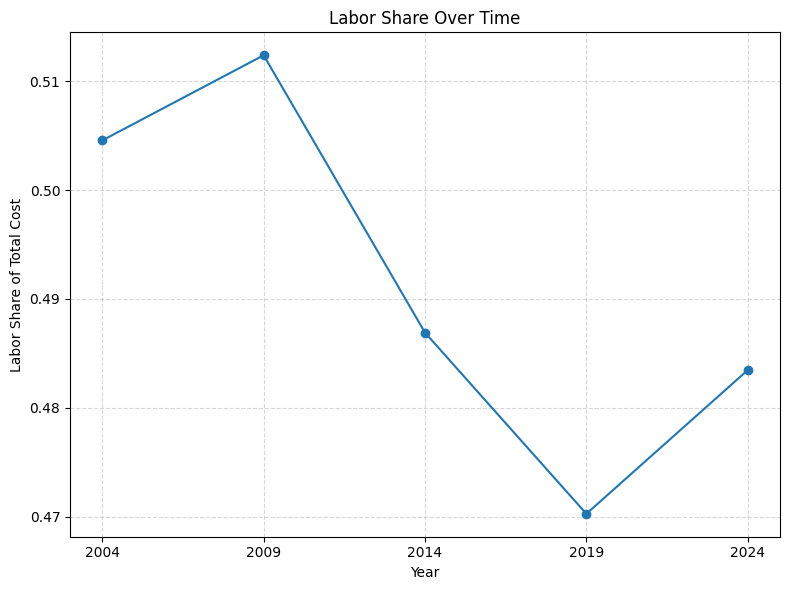

In [ ]:
import matplotlib.pyplot as plt

years = sorted(labor_by_year['YEAR'].unique())

plt.figure(figsize=(8,6))
plt.plot(labor_by_year['YEAR'], labor_by_year['Labor_Share'], marker='o')

plt.xlabel('Year')
plt.ylabel('Labor Share of Total Cost')
plt.title('Labor Share Over Time')

# Force correct year ticks
plt.xticks(years)

plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Slope: 1.9290899394827656
R^2: 0.9244841902330644


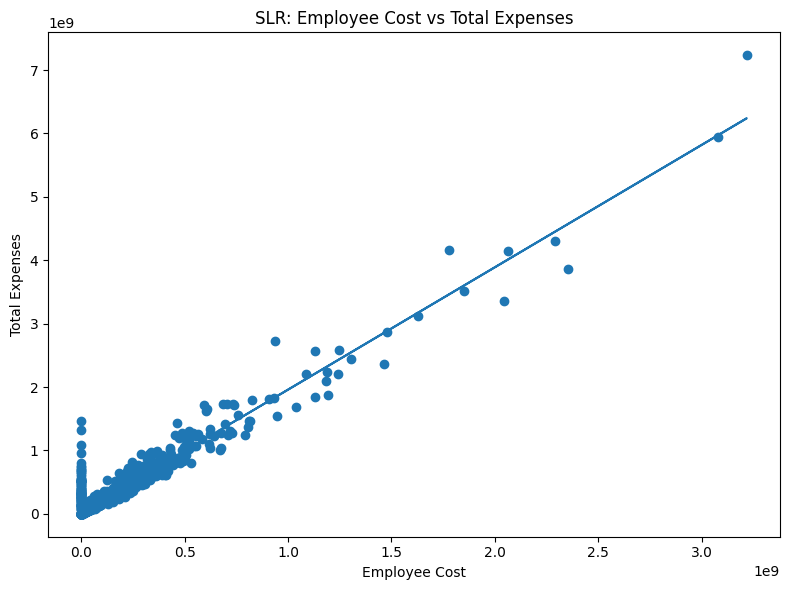

In [ ]:
# Variables
X = merged_with_end_year[['Employee_Cost']]
y = merged_with_end_year['Total_Combined_Expenses']

# Fit model
model = LinearRegression().fit(X, y)

# Predictions for line
y_pred = model.predict(X)
print("Slope:", model.coef_[0])
print("R^2:", model.score(X, y))
# -----------------------------
# Plot
# -----------------------------
plt.figure(figsize=(8,6))

# Scatter points
plt.scatter(X, y)

# Regression line
plt.plot(X, y_pred)

# Labels
plt.xlabel('Employee Cost')
plt.ylabel('Total Expenses')
plt.title('SLR: Employee Cost vs Total Expenses')

plt.tight_layout()
plt.show()

In [ ]:
merged_with_end_year['Cost_per_FTE'] = (
    merged_with_end_year['Employee_Cost'] /
    merged_with_end_year['HOSP_FTE']
)
merged_with_end_year.columns

Index(['FAC_NO', 'FAC_NAME', 'BEG_DATE', 'END_DATE', 'DAY_PER', 'DATA_IND',
       'AUDIT_IND', 'COUNTY', 'HSA', 'HFPA', 'TYPE_CNTRL', 'TYPE_CARE',
       'TYPE_HOSP', 'TEACH_RURL', 'PHONE', 'ADDRESS', 'CITY', 'ZIP_CODE',
       'CEO', 'CEO_TITLE', 'WEB_SITE', 'OWNER', 'DAY_TOT', 'DIS_TOT',
       'DIS_NURSRY', 'VIS_TOT', 'VIS_ER', 'VIS_CLIN', 'VIS_REF_OP',
       'OP_MIN_IP', 'OP_MIN_OP', 'SURG_IP', 'SURG_OP', 'C_SECTIONS', 'EXP_DLY',
       'EXP_AMB', 'EXP_ANC', 'EXP_PIP', 'EXP_POP', 'EXP_RES', 'EXP_ED',
       'EXP_GEN', 'EXP_FISC', 'EXP_ADM', 'EXP_UNASSG', 'EXP_SAL', 'EXP_BEN',
       'EXP_PHYS', 'EXP_OTHPRO', 'EXP_SUPP', 'EXP_PURCH', 'EXP_DEPRE',
       'EXP_LEASES', 'EXP_INSUR', 'EXP_INTRST', 'EXP_OTH', 'HOSP_FTE',
       'NURS_FTE', 'PROD_HRS', 'NON_PRD_HR', 'PAID_HRS', 'MED_STAFF',
       'STDNT_FTE', 'PRD_HR_DLY', 'PRD_HR_AMB', 'PRD_HR_ANC', 'PRD_HR_ED',
       'PRD_HR_GEN', 'PRD_HR_FIS', 'PRD_HR_ADM', 'PRD_HR_NON', 'PD_HR_DLY',
       'PD_HR_AMB', 'PD_HR_ANC', 'PD_HR_ED', 'PD

In [ ]:
# 1. Aggregate data by year (or filter for specific years)
summary = merged_with_end_year.groupby('YEAR').agg({
    'HOSP_FTE': 'sum',
    'Employee_Cost': 'sum'
}).reset_index()

# 2. Calculate Average Rate per FTE
summary['Rate_per_FTE'] = summary['Employee_Cost'] / summary['HOSP_FTE']

# 3. Create 'Prior Year' columns to compare
summary['Prev_FTE'] = summary['HOSP_FTE'].shift(1)
summary['Prev_Rate'] = summary['Rate_per_FTE'].shift(1)

# 4. Calculate the Bridge Components
summary['Headcount_Effect'] = (summary['HOSP_FTE'] - summary['Prev_FTE']) * summary['Prev_Rate']
summary['Rate_Effect'] = (summary['Rate_per_FTE'] - summary['Prev_Rate']) * summary['Prev_FTE']
summary['Interaction_Effect'] = (summary['HOSP_FTE'] - summary['Prev_FTE']) * (summary['Rate_per_FTE'] - summary['Prev_Rate'])

# 5. Check: Sum of effects should equal the total change in Employee_Cost
summary['Total_Change'] = summary['Employee_Cost'].diff()

In [ ]:
summary.head()

,YEAR,HOSP_FTE,Employee_Cost,Rate_per_FTE,Prev_FTE,Prev_Rate,Headcount_Effect,Rate_Effect,Interaction_Effect,Total_Change
0,2004,315237,21913782490,69515.261502,NaN,NaN,NaN,NaN,NaN,NaN
1,2009,392551,32109813789,81797.814269,315237.0,69515.261502,5.374503e+09,3.871915e+09,9.496133e+08,1.019603e+10
2,2014,378683,39068892100,103170.440976,392551.0,81797.814269,-1.134372e+09,8.389846e+09,-2.963956e+08,6.959078e+09
3,2019,421391,51951300513,123285.263598,378683.0,103170.440976,4.406203e+09,7.617141e+09,8.590638e+08,1.288241e+10
4,2024,475781,75728198154,159166.083038,421391.0,123285.263598,6.705485e+09,1.511985e+10,1.951558e+09,2.377690e+10


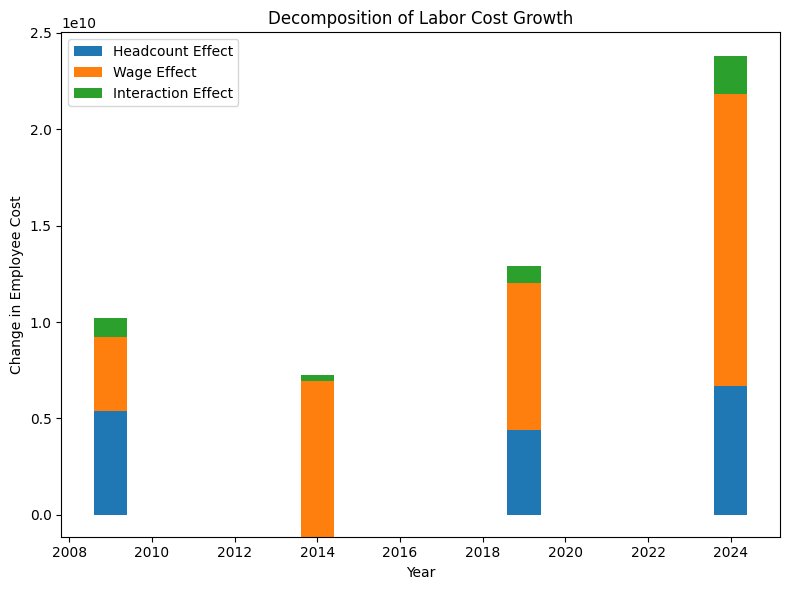

In [ ]:
years = summary['YEAR'][1:]  # skip first (no prior year)

head = summary['Headcount_Effect'][1:]
rate = summary['Rate_Effect'][1:]
interaction = summary['Interaction_Effect'][1:]

plt.figure(figsize=(8,6))

plt.bar(years, head, label='Headcount Effect')
plt.bar(years, rate, bottom=head, label='Wage Effect')
plt.bar(years, interaction, bottom=head + rate, label='Interaction Effect')

plt.xlabel('Year')
plt.ylabel('Change in Employee Cost')
plt.title('Decomposition of Labor Cost Growth')

plt.legend()
plt.tight_layout()
plt.show()

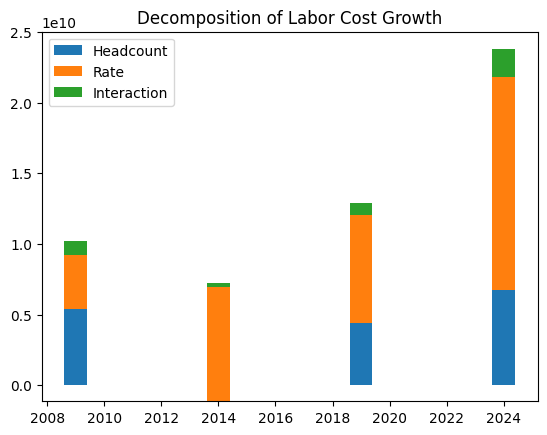

In [ ]:
plt.bar(summary['YEAR'][1:], summary['Headcount_Effect'][1:], label='Headcount')
plt.bar(summary['YEAR'][1:], summary['Rate_Effect'][1:], bottom=summary['Headcount_Effect'][1:], label='Rate')
plt.bar(summary['YEAR'][1:], summary['Interaction_Effect'][1:],
        bottom=summary['Headcount_Effect'][1:] + summary['Rate_Effect'][1:], label='Interaction')

plt.legend()
plt.title('Decomposition of Labor Cost Growth')
plt.show()

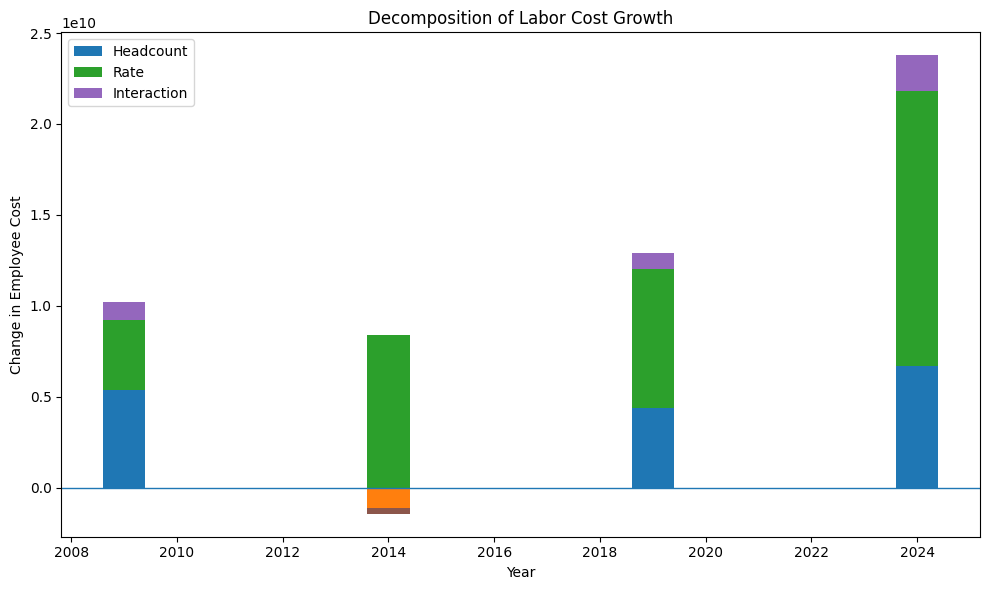

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

years = summary['YEAR'][1:]

head = summary['Headcount_Effect'][1:]
rate = summary['Rate_Effect'][1:]
interaction = summary['Interaction_Effect'][1:]

plt.figure(figsize=(10,6))

# Initialize bottoms
pos_bottom = np.zeros(len(years))
neg_bottom = np.zeros(len(years))

# Function to plot properly
def stacked_bar(values, label):
    global pos_bottom, neg_bottom

    pos_vals = np.where(values > 0, values, 0)
    neg_vals = np.where(values < 0, values, 0)

    plt.bar(years, pos_vals, bottom=pos_bottom, label=label)
    plt.bar(years, neg_vals, bottom=neg_bottom)

    pos_bottom += pos_vals
    neg_bottom += neg_vals

# Plot each component
stacked_bar(head.values, 'Headcount')
stacked_bar(rate.values, 'Rate')
stacked_bar(interaction.values, 'Interaction')

# Formatting
plt.axhline(0, linewidth=1)  # zero line
plt.xlabel('Year')
plt.ylabel('Change in Employee Cost')
plt.title('Decomposition of Labor Cost Growth')

plt.legend()
plt.tight_layout()
plt.show()

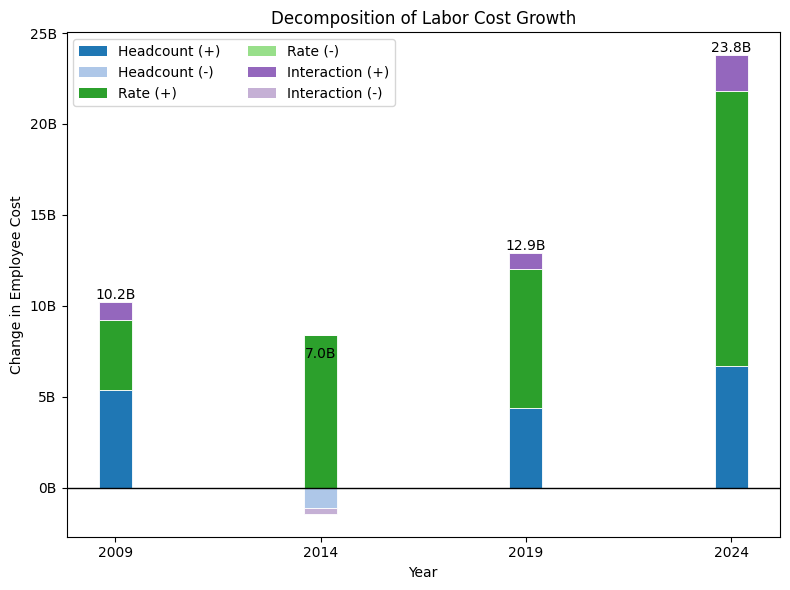

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import matplotlib.ticker as mtick

# -----------------------------
# Data
# -----------------------------
years = summary['YEAR'].iloc[1:].astype(int).to_list()

head = summary['Headcount_Effect'].iloc[1:].to_numpy()
rate = summary['Rate_Effect'].iloc[1:].to_numpy()
interaction = summary['Interaction_Effect'].iloc[1:].to_numpy()

# -----------------------------
# Colors
# -----------------------------
head_pos_color = '#1f77b4'
head_neg_color = '#aec7e8'

rate_pos_color = '#2ca02c'
rate_neg_color = '#98df8a'

int_pos_color = '#9467bd'
int_neg_color = '#c5b0d5'

# -----------------------------
# Plot
# -----------------------------
fig, ax = plt.subplots(figsize=(8, 6))

pos_bottom = np.zeros(len(years))
neg_bottom = np.zeros(len(years))

def plot_positive_negative(values, pos_color, neg_color):
    global pos_bottom, neg_bottom

    pos_vals = np.where(values > 0, values, 0)
    neg_vals = np.where(values < 0, values, 0)

    ax.bar(years, pos_vals, bottom=pos_bottom, color=pos_color, edgecolor='white', linewidth=0.6)
    ax.bar(years, neg_vals, bottom=neg_bottom, color=neg_color, edgecolor='white', linewidth=0.6)

    pos_bottom += pos_vals
    neg_bottom += neg_vals

# Add each component
plot_positive_negative(head, head_pos_color, head_neg_color)
plot_positive_negative(rate, rate_pos_color, rate_neg_color)
plot_positive_negative(interaction, int_pos_color, int_neg_color)

# Zero line
ax.axhline(0, color='black', linewidth=1)

# Labels and title
ax.set_xlabel('Year')
ax.set_ylabel('Change in Employee Cost')
ax.set_title('Decomposition of Labor Cost Growth')

# Cleaner x-axis
ax.set_xticks(years)

# Optional: format y-axis in billions
ax.ticklabel_format(style='plain', axis='y')

# Proper legend
legend_handles = [
    Patch(facecolor=head_pos_color, label='Headcount (+)'),
    Patch(facecolor=head_neg_color, label='Headcount (-)'),
    Patch(facecolor=rate_pos_color, label='Rate (+)'),
    Patch(facecolor=rate_neg_color, label='Rate (-)'),
    Patch(facecolor=int_pos_color, label='Interaction (+)'),
    Patch(facecolor=int_neg_color, label='Interaction (-)'),
]

ax.legend(handles=legend_handles, loc='upper left', frameon=True, ncol=2)
ax = plt.gca()
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x/1e9:.0f}B'))

for i, year in enumerate(years):
    total = head[i] + rate[i] + interaction[i]
    ax.text(year, total, f'{total/1e9:.1f}B',
            ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

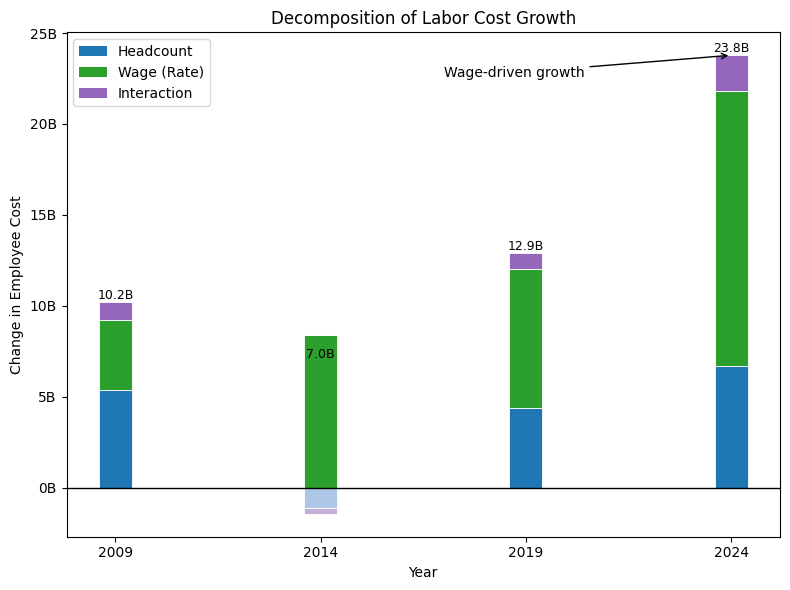

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch

# -------------------------------------------------
# Assumes you already have `summary` created as:
# YEAR, Headcount_Effect, Rate_Effect, Interaction_Effect
# -------------------------------------------------

# Keep only years after the first one (since the first has no prior-year comparison)
plot_df = summary.iloc[1:].copy()

years = plot_df['YEAR'].astype(int).to_list()
head = plot_df['Headcount_Effect'].to_numpy()
rate = plot_df['Rate_Effect'].to_numpy()
interaction = plot_df['Interaction_Effect'].to_numpy()

# Colors
head_pos_color = '#1f77b4'   # blue
head_neg_color = '#aec7e8'   # light blue
rate_pos_color = '#2ca02c'   # green
rate_neg_color = '#98df8a'   # light green
int_pos_color = '#9467bd'    # purple
int_neg_color = '#c5b0d5'    # light purple

fig, ax = plt.subplots(figsize=(8, 6))

pos_bottom = np.zeros(len(years))
neg_bottom = np.zeros(len(years))

def add_stacked_component(values, pos_color, neg_color):
    global pos_bottom, neg_bottom

    pos_vals = np.where(values > 0, values, 0)
    neg_vals = np.where(values < 0, values, 0)

    ax.bar(years, pos_vals, bottom=pos_bottom, color=pos_color,
           edgecolor='white', linewidth=0.6)
    ax.bar(years, neg_vals, bottom=neg_bottom, color=neg_color,
           edgecolor='white', linewidth=0.6)

    pos_bottom += pos_vals
    neg_bottom += neg_vals

# Add components
add_stacked_component(head, head_pos_color, head_neg_color)
add_stacked_component(rate, rate_pos_color, rate_neg_color)
add_stacked_component(interaction, int_pos_color, int_neg_color)

# Zero line
ax.axhline(0, color='black', linewidth=1)

# Labels and title
ax.set_xlabel('Year')
ax.set_ylabel('Change in Employee Cost')
ax.set_title('Decomposition of Labor Cost Growth')

# X-axis ticks
ax.set_xticks(years)

# Y-axis in billions
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x/1e9:.0f}B'))

# Legend: grouped by category, not by sign
legend_handles = [
    Patch(facecolor=head_pos_color, label='Headcount'),
    Patch(facecolor=rate_pos_color, label='Wage (Rate)'),
    Patch(facecolor=int_pos_color, label='Interaction'),
]
ax.legend(handles=legend_handles, loc='upper left', frameon=True)

# Optional annotations: label totals on top / bottom
for i, year in enumerate(years):
    total = head[i] + rate[i] + interaction[i]
    y_pos = total if total >= 0 else total
    va = 'bottom' if total >= 0 else 'top'
    ax.text(year, y_pos, f'{total/1e9:.1f}B', ha='center', va=va, fontsize=9)

# Optional callout
ax.annotate(
    'Wage-driven growth',
    xy=(years[-1], head[-1] + rate[-1] + interaction[-1]),
    xytext=(years[-1] - 7, max(pos_bottom.max(), 0) * 0.95),
    arrowprops=dict(arrowstyle='->', lw=1),
    fontsize=10
)

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path

# Define the target folder path
output_folder = Path("/content/drive/MyDrive/Hospital_Data/GN_data")
output_folder.mkdir(parents=True, exist_ok=True)

# Define the output file path
output_file_path = output_folder / "merged_hospital_data.csv"

# Save the DataFrame to CSV
merged_with_end_year.to_csv(output_file_path, index=False)

print(f"DataFrame saved to: {output_file_path}")

DataFrame saved to: /content/drive/MyDrive/Hospital_Data/GN_data/merged_hospital_data.csv
